# MEAI502 · Lab 5 · The Date Detective 🌴
## A complete machine learning project: from a customer complaint to a working sorting gate

**Course:** MEAI502 Applied Machine Learning · **Instructor:** Dr. Naila Marir · Effat College of Engineering
**Duration:** 150 minutes · **Tools:** Python, pandas, scikit-learn, Google Colab

---

## 📜 The case

Abu Fahad owns a **date-packing factory in Buraydah**. Every day thousands of dates pass on a belt, and his workers sort them **by eye** into 7 varieties.

Last week a big customer called, angry:
> *"I paid for premium **Safawi** boxes. Inside I found other dates mixed in!"*

Sorting by eye is slow, tiring, and full of mistakes. But Abu Fahad already has a **camera** above the belt. For every date it measures **34 numbers**: its size, its shape and its colour.

He hires **you** as the data scientist:
> *"Can you build a model that tells me **which variety** each date is, and **warns me when it is not sure**?"*

Today you will solve this case **from start to finish**, exactly like a real ML project.

### How to work
1. Run the cells **from top to bottom** (`Shift + Enter`).
2. Cells marked **`# TODO`** are yours. Replace every `...` with your code.
3. A **✅ check** cell follows most TODOs. If it prints ✅, move on.
4. Answer the **✍️ questions** in the text cells, in your own words.

### Learning outcomes
By the end of this lab you can:
1. Turn a real business request into a machine learning task.
2. Explore, check and clean a real dataset (including finding a broken measurement).
3. Explain **why feature scaling matters**, and prove it with an experiment.
4. Train a **multiclass** logistic regression with **one-vs-all**.
5. Read a **7 × 7 confusion matrix** and per-class precision and recall.
6. Compare groups of features to find which clues matter most.
7. Use `predict_proba` to build an application that **knows when it is not sure**.


| Step | Mission | Time |
|---|---|---|
| 0 | Setup and get the evidence (download the data) | 10 min |
| 1 | Understand the mission | 5 min |
| 2 | Open the evidence | 10 min |
| 3 | Know your clues | 10 min |
| 4 | Prepare the evidence | 15 min |
| 5 | The lazy detective (baseline) | 5 min |
| 6 | The first detective (2 clues) | 15 min |
| 7 | The full detective (34 clues) | 15 min |
| 8 | Who gets confused? | 20 min |
| 9 | A smarter detective | 15 min |
| 10 | The application: the Sorting Gate | 20 min |
| 11 | Report to Abu Fahad | 10 min |
| ★ | Optional challenge: a colour-only Sorting Gate | extra |

---
# Step 0 · Setup and get the evidence 🧰

### 0.1 Download the data from Kaggle (do this once)
1. Open **https://www.kaggle.com/datasets/muratkokludataset/date-fruit-datasets**
2. Sign in (a free Kaggle account is enough).
3. Click **Download**. You get a file called `archive.zip`. **Do not unzip it.**
4. Run the cell below and **upload `archive.zip`** when the *Choose Files* button appears.

> The dataset comes from a real research paper: Koklu, M. et al. (2021), *Classification of Date Fruits into Genetic Varieties Using Image Analysis*, Mathematical Problems in Engineering. Remember their result: **logistic regression reached 91.0 %**. Can you match it?

In [1]:
# Run this cell. It imports the libraries and loads the data file you upload.
import os, glob, zipfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

FILE = "Date_Fruit_Datasets.xlsx"

def find_data_file():
    # 1) the Excel file is already here
    hits = glob.glob(f"**/{FILE}", recursive=True)
    if hits:
        return hits[0]
    # 2) a zip was uploaded: unzip it
    for z in glob.glob("*.zip"):
        with zipfile.ZipFile(z) as zf:
            zf.extractall("date_data")
    hits = glob.glob(f"**/{FILE}", recursive=True)
    return hits[0] if hits else None

path = find_data_file()
if path is None:
    from google.colab import files
    print("Please upload archive.zip (or Date_Fruit_Datasets.xlsx) from Kaggle")
    files.upload()
    path = find_data_file()

print("Data file found:", path)
np.random.seed(42)

Please upload archive.zip (or Date_Fruit_Datasets.xlsx) from Kaggle


Saving archive.zip to archive.zip
Data file found: date_data/Date_Fruit_Datasets/Date_Fruit_Datasets.xlsx


---
# Step 1 · Understand the mission 🎯

Before writing any code, a good data scientist translates the request into an ML task.

> *"Tell me **which variety** each date is, using the camera's **34 measurements**."*

✍️ **Q1.** Fill in the blanks:
- The **input** `X` of our model is:
- The **output** `y` of our model is:
- Is this **regression** or **classification**? Why?
- Is it **binary** or **multiclass**?
- What does Abu Fahad gain if the model works? What does he lose if it makes mistakes?

✍️ **Your answer (Q1):**
- The **input** `X` of our model is: 34 measurements of one date
- The **output** `y` of our model is: variety of date
- Is this **regression** or **classification**? Why? Classification because the output is a category, not a number.
- Is it **binary** or **multiclass**? Multiclass
- What does Abu Fahad gain if the model works? What does he lose if it makes mistakes?
He gains a sorting system if the model works and he will get customer complaints if the model makes mistakes.

---
# Step 2 · Open the evidence 🗂️

Load the Excel file into a DataFrame and look at it.

In [2]:
# TODO: read the Excel file into a DataFrame called df
df = pd.read_excel("date_data/Date_Fruit_Datasets/Date_Fruit_Datasets.xlsx")

# TODO: print the shape of df (rows, columns)
print(df.shape)

df.head()

(898, 35)


,AREA,PERIMETER,MAJOR_AXIS,MINOR_AXIS,ECCENTRICITY,EQDIASQ,SOLIDITY,CONVEX_AREA,EXTENT,ASPECT_RATIO,...,KurtosisRR,KurtosisRG,KurtosisRB,EntropyRR,EntropyRG,EntropyRB,ALLdaub4RR,ALLdaub4RG,ALLdaub4RB,Class
0,422163,2378.908,837.8484,645.6693,0.6373,733.1539,0.9947,424428,0.7831,1.2976,...,3.2370,2.9574,4.2287,-59191263232,-50714214400,-39922372608,58.7255,54.9554,47.8400,BERHI
1,338136,2085.144,723.8198,595.2073,0.5690,656.1464,0.9974,339014,0.7795,1.2161,...,2.6228,2.6350,3.1704,-34233065472,-37462601728,-31477794816,50.0259,52.8168,47.8315,BERHI
2,526843,2647.394,940.7379,715.3638,0.6494,819.0222,0.9962,528876,0.7657,1.3150,...,3.7516,3.8611,4.7192,-93948354560,-74738221056,-60311207936,65.4772,59.2860,51.9378,BERHI
3,416063,2351.210,827.9804,645.2988,0.6266,727.8378,0.9948,418255,0.7759,1.2831,...,5.0401,8.6136,8.2618,-32074307584,-32060925952,-29575010304,43.3900,44.1259,41.1882,BERHI
4,347562,2160.354,763.9877,582.8359,0.6465,665.2291,0.9908,350797,0.7569,1.3108,...,2.7016,2.9761,4.4146,-39980974080,-35980042240,-25593278464,52.7743,50.9080,42.6666,BERHI


In [3]:
# ✅ Check
assert df.shape == (898, 35), "df should have 898 rows and 35 columns. Did you read the right file?"
print("✅ Evidence loaded:", df.shape[0], "dates,", df.shape[1] - 1, "measurements + 1 label column")

✅ Evidence loaded: 898 dates, 34 measurements + 1 label column


Now count how many dates we have of each variety. The label column is called **`Class`**.
> 📝 The file uses its own labels (BERHI, DEGLET, DOKOL, IRAQI, ROTANA, SAFAVI, SOGAY). We use them as they are.

Class
DOKOL     204
SAFAVI    199
ROTANA    166
DEGLET     98
SOGAY      94
IRAQI      72
BERHI      65
Name: count, dtype: int64


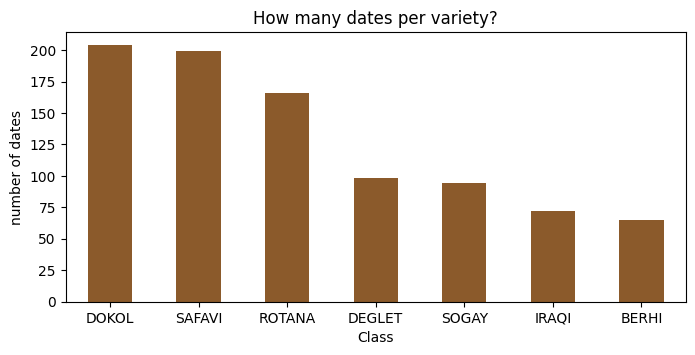

In [4]:
# TODO: count the number of dates per variety (hint: value_counts)
counts = df['Class'].value_counts()
print(counts)

counts.plot(kind="bar", color="#8B5A2B", figsize=(8, 3.5), title="How many dates per variety?")
plt.ylabel("number of dates"); plt.xticks(rotation=0); plt.show()

In [5]:
# ✅ Check
assert len(counts) == 7 and counts.sum() == 898
print("✅ 7 varieties found. Smallest:", counts.idxmin(), counts.min(), "| Largest:", counts.idxmax(), counts.max())

✅ 7 varieties found. Smallest: BERHI 65 | Largest: DOKOL 204


✍️ **Q2.** Which variety has the **fewest** dates? Which has the **most**? Why could this imbalance be a problem for a model?

✍️ **Your answer (Q2):**

BERHI has the fewest dates while DOKOL has the most. The model may learn big classes well and small classes badly. We need to regularize.

---
# Step 3 · Know your clues 🔎

The 34 measurements belong to **three families of clues**:

| Family | What it describes | Columns |
|---|---|---|
| 📏 **Size** (6) | How big the date is | AREA, PERIMETER, MAJOR_AXIS, MINOR_AXIS, EQDIASQ, CONVEX_AREA |
| 🔷 **Shape** (10) | How round or long it is | ECCENTRICITY, SOLIDITY, EXTENT, ASPECT_RATIO, ROUNDNESS, COMPACTNESS, SHAPEFACTOR_1–4 |
| 🎨 **Colour** (18) | Statistics of the red, green and blue pixels | Mean, StdDev, Skew, Kurtosis, Entropy, ALLdaub4 × (RR, RG, RB) |

In [6]:
# Run this cell: it defines the three families of clues
SIZE   = ["AREA", "PERIMETER", "MAJOR_AXIS", "MINOR_AXIS", "EQDIASQ", "CONVEX_AREA"]
SHAPE  = ["ECCENTRICITY", "SOLIDITY", "EXTENT", "ASPECT_RATIO", "ROUNDNESS", "COMPACTNESS",
          "SHAPEFACTOR_1", "SHAPEFACTOR_2", "SHAPEFACTOR_3", "SHAPEFACTOR_4"]
COLOUR = [c for c in df.columns if c not in SIZE + SHAPE + ["Class"]]
print(len(SIZE), "size +", len(SHAPE), "shape +", len(COLOUR), "colour =", len(SIZE + SHAPE + COLOUR), "clues")

VARIETIES = sorted(df["Class"].unique())
PALETTE = dict(zip(VARIETIES, ["#2E86AB", "#E67E22", "#8E44AD", "#27AE60", "#C0392B", "#3E2723", "#7F8C8D"]))

def scatter_two_clues(data, x_col, y_col):
    plt.figure(figsize=(7, 5))
    for v in VARIETIES:
        part = data[data["Class"] == v]
        plt.scatter(part[x_col], part[y_col], s=14, alpha=0.7, label=v, color=PALETTE[v])
    plt.xlabel(x_col); plt.ylabel(y_col); plt.legend(markerscale=2, fontsize=8)
    plt.title(f"Each dot is one date: {x_col} vs {y_col}"); plt.show()

6 size + 10 shape + 18 colour = 34 clues


In [7]:
print(df.columns)

Index(['AREA', 'PERIMETER', 'MAJOR_AXIS', 'MINOR_AXIS', 'ECCENTRICITY',
       'EQDIASQ', 'SOLIDITY', 'CONVEX_AREA', 'EXTENT', 'ASPECT_RATIO',
       'ROUNDNESS', 'COMPACTNESS', 'SHAPEFACTOR_1', 'SHAPEFACTOR_2',
       'SHAPEFACTOR_3', 'SHAPEFACTOR_4', 'MeanRR', 'MeanRG', 'MeanRB',
       'StdDevRR', 'StdDevRG', 'StdDevRB', 'SkewRR', 'SkewRG', 'SkewRB',
       'KurtosisRR', 'KurtosisRG', 'KurtosisRB', 'EntropyRR', 'EntropyRG',
       'EntropyRB', 'ALLdaub4RR', 'ALLdaub4RG', 'ALLdaub4RB', 'Class'],
      dtype='object')


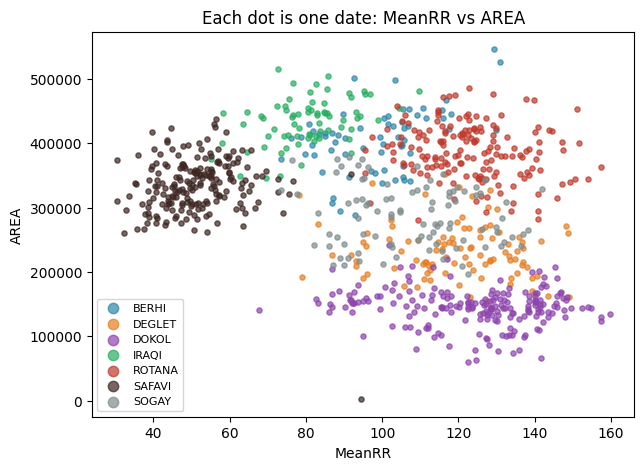

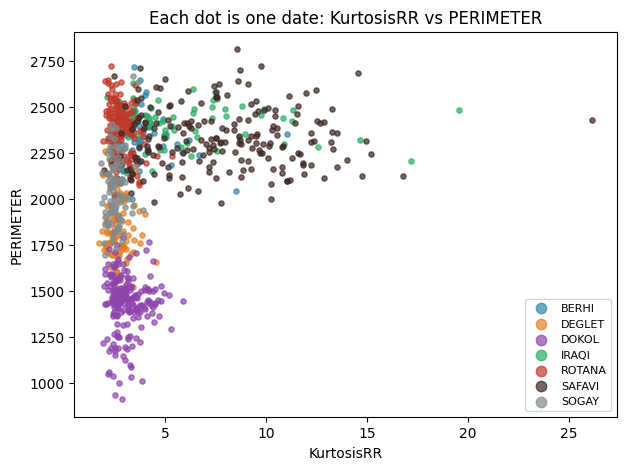

In [8]:
# TODO: choose ONE colour clue and ONE size clue and plot them
#x_col = "MeanRR" #average redness
#y_col = "AREA" #size
scatter_two_clues(df, x_col = "MeanRR", y_col = "AREA")
scatter_two_clues(df, x_col = "KurtosisRR", y_col = "PERIMETER")

✍️ **Q3.** Looking at your plot: which varieties form their **own clear group**? Which varieties **overlap** (hard to separate)? Do you see any **strange dot** that does not look like a real date? Try one more pair of clues and compare.

✍️ **Your answer (Q3):**

The most clear group is DOKOL. The varieties that overlap are: DEGLET & SOGAY and BERHI & ROTANA & IRAQI.

There exist dots outside of the clusters that don't look like real dates, mostly of type SAFAVI.

---
# Step 4 · Prepare the evidence 🧹

### 4.1 Missing values and duplicates

In [9]:
# TODO: count the missing values in the whole DataFrame (hint: isna().sum().sum())
n_missing = df.isna().sum().sum()
# TODO: count duplicated rows (hint: duplicated().sum())
n_duplicates = df.duplicated().sum()
print("Missing values:", n_missing, "| Duplicated rows:", n_duplicates)

Missing values: 0 | Duplicated rows: 0


In [10]:
# ✅ Check
assert n_missing == 0 and n_duplicates == 0
print("✅ Clean: no missing values and no duplicates")

✅ Clean: no missing values and no duplicates


### 4.2 🕵️ The suspicious date

No missing values does **not** mean the data is correct. Let's look at the smallest and largest value of each size clue.

In [11]:
df[SIZE + ["ASPECT_RATIO"]].describe().loc[["min", "50%", "max"]].round(1)

,AREA,PERIMETER,MAJOR_AXIS,MINOR_AXIS,EQDIASQ,CONVEX_AREA,ASPECT_RATIO
min,1987.0,911.8,336.7,2.3,50.3,2257.0,1.1
50%,319833.0,2196.3,791.4,495.1,638.1,327207.0,1.5
max,546063.0,2812.0,1222.7,766.5,833.8,552598.0,535.5


Look at **MINOR_AXIS** (the width of the date, in pixels): the typical date is about 400 pixels wide, but the minimum is about **2 pixels**!

In [12]:
# TODO: show the row(s) where MINOR_AXIS is smaller than 100
suspicious = df[df["MINOR_AXIS"] < 100]
suspicious[["AREA", "MAJOR_AXIS", "MINOR_AXIS", "ASPECT_RATIO", "Class"]]

,AREA,MAJOR_AXIS,MINOR_AXIS,ASPECT_RATIO,Class
615,1987,1222.723,2.2832,535.5257,SAFAVI


✍️ **Q4.** Can a real date be about 900 pixels long and only 2 pixels wide? What probably happened? What should we do with this row?

✍️ **Your answer (Q4):**

No, a real date cannot be 900 pixels long and only 2 pixels wide. The camera detected it wrong, segmentation error. We should delete those entries.

In [13]:
# TODO: keep only the rows where MINOR_AXIS is at least 100
df = df[df["MINOR_AXIS"] >= 100]
print(df.shape)

(897, 35)


In [14]:
# ✅ Check
assert df.shape == (897, 35), "You should have 897 dates left"
print("✅ Broken measurement removed. 897 dates left.")

✅ Broken measurement removed. 897 dates left.


### 4.3 Split the evidence: training set and test set

We keep **20 %** of the dates hidden. The model never sees them during training; we use them at the end, like a final exam.
`stratify=y` keeps the same proportion of each variety in both sets.

In [15]:
X = df.drop(columns="Class")
y = df["Class"]

# TODO: split into train (80%) and test (20%), with stratify=y and random_state=42
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (717, 34) | Test: (180, 34)


In [16]:
# ✅ Check
assert X_train.shape == (717, 34) and X_test.shape == (180, 34)
print("✅ 717 dates for training, 180 hidden for the final exam")

✅ 717 dates for training, 180 hidden for the final exam


### 4.4 Different units, very different numbers

In [17]:
X_train[["AREA", "ECCENTRICITY", "MeanRR"]].agg(["min", "max"]).round(2)

,AREA,ECCENTRICITY,MeanRR
min,63328,0.38,30.38
max,546063,0.90,159.65


✍️ **Q5.** AREA goes up to about 550,000 while ECCENTRICITY stays between 0 and 1. Why could this be a problem for gradient descent? (We will **test** your answer in Step 7.)

✍️ **Your answer (Q5):**

The features have very different scales. AREA has much larger values than ECCENTRICITY, so it can have a bigger influence on the gradients. This can make gradient descent converge slowly or struggle to find the optimal solution.

---
# Step 5 · The lazy detective (baseline) 😴

A lazy detective does not look at the evidence. He always answers **the most common variety**.
Any real model **must beat** this score; otherwise it learned nothing.

In [18]:
# TODO: create a DummyClassifier with strategy="most_frequent", fit it on the training set
lazy = DummyClassifier(strategy="most_frequent")
lazy.fit(X_train, y_train)

# TODO: compute its accuracy on the test set
lazy_acc = lazy.score(X_test, y_test)
print(f"Lazy detective accuracy: {lazy_acc:.1%}")

Lazy detective accuracy: 22.8%


In [19]:
# ✅ Check
assert abs(lazy_acc - 0.228) < 0.01
print("✅ The lazy detective always says", lazy.predict(X_test[:1])[0], "and is right only", f"{lazy_acc:.1%}", "of the time")

✅ The lazy detective always says DOKOL and is right only 22.8% of the time


---
# Step 6 · The first detective: only 2 clues 🔍

We start small, with **2 clues**, so we can **see** what the model does.

Logistic regression is binary (yes / no). For **7 varieties** we use **one-vs-all** (Chapter 3, Part 6):
we train **one classifier per variety** ("Is it SAFAVI or not?", "Is it BERHI or not?", ...) and pick the variety with the **highest probability**.

In scikit-learn: `OneVsRestClassifier(LogisticRegression())`.

In [20]:
TWO_CLUES = ["MeanRR", "AREA"]

# TODO: build a pipeline: StandardScaler, then OneVsRestClassifier(LogisticRegression(max_iter=1000))
detective_2 = make_pipeline(StandardScaler(), OneVsRestClassifier(LogisticRegression(max_iter=1000)))

# TODO: fit it on the training set, using ONLY the two clues
detective_2.fit(X_train[TWO_CLUES],y_train)

acc_2 = accuracy_score(y_test, detective_2.predict(X_test[TWO_CLUES]))
print(f"Detective with 2 clues: {acc_2:.1%}")

Detective with 2 clues: 76.1%


In [21]:
# ✅ Check
n_classifiers = len(detective_2[-1].estimators_)
assert n_classifiers == 7
print(f"✅ One-vs-all trained {n_classifiers} binary classifiers (one per variety). Accuracy: {acc_2:.1%}")

✅ One-vs-all trained 7 binary classifiers (one per variety). Accuracy: 76.1%


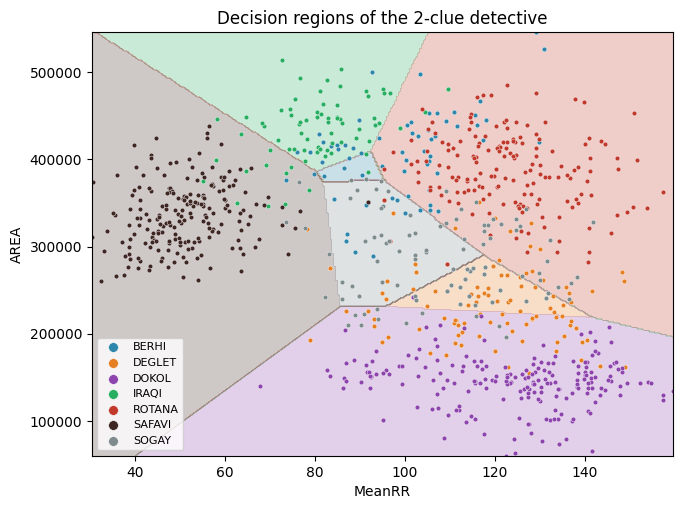

In [22]:
# Run this cell: it colours the map by the variety the detective would choose
def plot_decision_regions(model, data, x_col, y_col):
    xx, yy = np.meshgrid(np.linspace(data[x_col].min(), data[x_col].max(), 300),
                         np.linspace(data[y_col].min(), data[y_col].max(), 300))
    grid = pd.DataFrame({x_col: xx.ravel(), y_col: yy.ravel()})
    zz = pd.Series(model.predict(grid)).map({v: i for i, v in enumerate(VARIETIES)}).values.reshape(xx.shape)
    plt.figure(figsize=(7.5, 5.5))
    plt.contourf(xx, yy, zz, levels=np.arange(-0.5, 7), colors=[PALETTE[v] for v in VARIETIES], alpha=0.25)
    for v in VARIETIES:
        part = data[data["Class"] == v]
        plt.scatter(part[x_col], part[y_col], s=12, color=PALETTE[v], label=v, edgecolor="white", linewidth=0.3)
    plt.xlabel(x_col); plt.ylabel(y_col); plt.legend(markerscale=2, fontsize=8)
    plt.title("Decision regions of the 2-clue detective"); plt.show()

plot_decision_regions(detective_2, df, "MeanRR", "AREA")

✍️ **Q6.** (a) How many binary classifiers does one-vs-all train here, and why? (b) Are the borders between regions straight or curved? Why? (c) Where does the 2-clue detective make mistakes?

✍️ **Your answer (Q6):**

a. One-vs-all trains one classifier per variety so it trains 7 classifiers in total.

b. The borders are straight.

c. Most mistakes happen in the center where it is very crowded.

---
# Step 7 · The full detective: all 34 clues 🕵️‍♀️

In [23]:
# TODO: same pipeline as Step 6, but now fit it on ALL 34 clues (X_train)
detective = make_pipeline(StandardScaler(), OneVsRestClassifier(LogisticRegression(max_iter=1000)))
detective.fit(X_train, y_train)

acc_full = accuracy_score(y_test, detective.predict(X_test))
print(f"Full detective (34 clues): {acc_full:.1%}")
print("Published paper (logistic regression): 91.0%")

Full detective (34 clues): 91.7%
Published paper (logistic regression): 91.0%


In [24]:
# ✅ Check
assert acc_full > 0.88, "Your full detective should be above 88%. Did you use StandardScaler and all 34 clues?"
print("✅ Well done, detective!")

✅ Well done, detective!


### 🧪 Experiment: is scaling really important?
Remember your answer to **Q5**. Now we test it: train the **same** model **without** `StandardScaler`.

In [25]:
# TODO: train OneVsRestClassifier(LogisticRegression(max_iter=1000)) on X_train WITHOUT scaling
no_scaling = make_pipeline(OneVsRestClassifier(LogisticRegression(max_iter=1000)))
no_scaling.fit(X_train,y_train)

acc_no_scaling = accuracy_score(y_test, no_scaling.predict(X_test))
print(f"Without scaling: {acc_no_scaling:.1%}   |   With scaling: {acc_full:.1%}")

Without scaling: 60.6%   |   With scaling: 91.7%


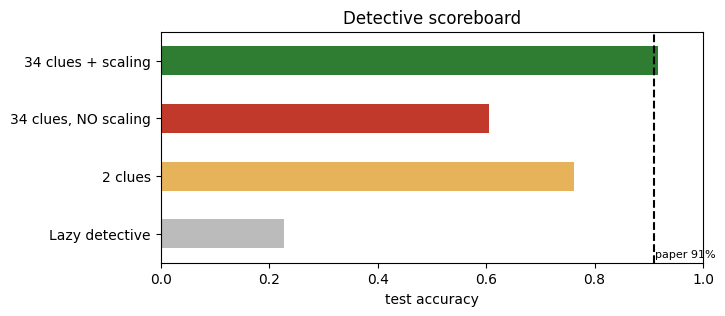

In [26]:
# Run this cell: the scoreboard so far
board = pd.Series({"Lazy detective": lazy_acc, "2 clues": acc_2,
                   "34 clues, NO scaling": acc_no_scaling, "34 clues + scaling": acc_full})
ax = board.plot(kind="barh", color=["#BBBBBB", "#E6B35A", "#C0392B", "#2E7D32"], figsize=(7, 3))
ax.axvline(0.91, ls="--", color="black"); ax.text(0.912, -0.4, "paper 91%", fontsize=8)
ax.set_xlim(0, 1); ax.set_xlabel("test accuracy"); ax.set_title("Detective scoreboard"); plt.show()

✍️ **Q7.** (a) How much accuracy did scaling add? Was your answer to Q5 correct? (b) Did your model match the paper's 91.0 %? (c) Why is it **fair** to compare with the paper only on the **test set**?

✍️ **Your answer (Q7):**

a. Scaling added more than 31 percent points of accuracy to the model. My answer to Q5 is verified here.

b. Yes, because my model achieved 91.7% accuracy.

c. It should only be compared with test set so as not to leak any data from training set.

---
# Step 8 · Who gets confused? 🤔

Accuracy is one number. The **confusion matrix** shows **which varieties** are mixed up.
Rows = the **true** variety. Columns = what the detective **predicted**.

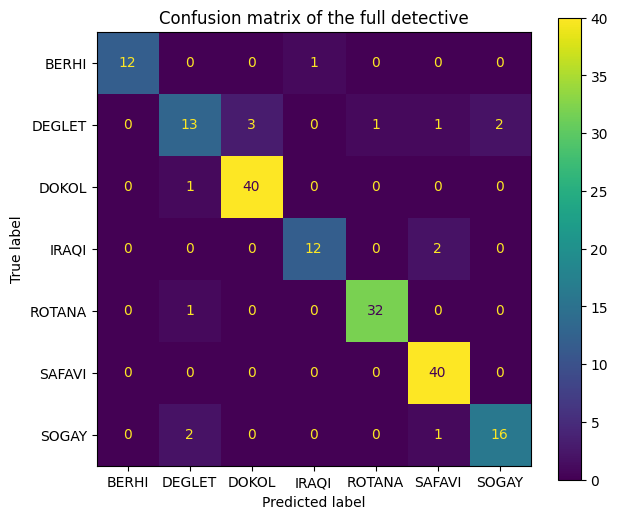

In [27]:
y_pred = detective.predict(X_test)

# TODO: draw the confusion matrix (hint: ConfusionMatrixDisplay.from_predictions(y_test, y_pred, ...))
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, ax=ax)
plt.title("Confusion matrix of the full detective"); plt.show()
plt.show()

In [28]:
print(classification_report(y_test, y_pred, digits=2))

              precision    recall  f1-score   support

       BERHI       1.00      0.92      0.96        13
      DEGLET       0.76      0.65      0.70        20
       DOKOL       0.93      0.98      0.95        41
       IRAQI       0.92      0.86      0.89        14
      ROTANA       0.97      0.97      0.97        33
      SAFAVI       0.91      1.00      0.95        40
       SOGAY       0.89      0.84      0.86        19

    accuracy                           0.92       180
   macro avg       0.91      0.89      0.90       180
weighted avg       0.91      0.92      0.91       180



### 🕵️ Back to the complaint
The customer complained that **other dates were packed as SAFAVI**. In the matrix, that is the **SAFAVI column**, outside the diagonal.

In [29]:
# TODO: how many dates did the detective PREDICT as SAFAVI?
predicted_safavi = 44
# TODO: among them, how many were NOT really SAFAVI?
wrong_safavi = 4

print("Predicted SAFAVI:", predicted_safavi, "| Not really SAFAVI:", wrong_safavi)
print(f"SAFAVI precision = {(predicted_safavi - wrong_safavi) / predicted_safavi:.1%}")

Predicted SAFAVI: 44 | Not really SAFAVI: 4
SAFAVI precision = 90.9%


In [30]:
# ✅ Check
assert predicted_safavi == 44 and wrong_safavi == 4, "Count the SAFAVI column of the confusion matrix"
print("✅ Correct. Without any protection, 4 'fake Safawi' would reach the customer.")

✅ Correct. Without any protection, 4 'fake Safawi' would reach the customer.


✍️ **Q8.** (a) Which variety is the **hardest** to recognise (lowest recall)?

---

Which variety does it get confused with?
(b) For the Safawi complaint, which metric matters most: **precision** or **recall** of SAFAVI? Explain in one sentence.
(c) Why is overall accuracy not enough for Abu Fahad?

✍️ **Your answer (Q8):**

a. DEGLET has lowest recall so it is hardest to recognize and DEGLET is most often confused with DOKOL.

b. Precision matters more because precision tells us how many dates predicted as SAFAVI are actually SAFAVI, helping us understand whether other varieties are incorrectly labelled as SAFAVI.

c. Overall accuracy is not enough because it hides the performance differences between individual varieties. Even though the model has 92% accuracy, it struggles to recognise DEGLET dates correctly. Abu Fahad's complaint is about precision.

---
# Step 9 · A smarter detective: which clues matter most? 🧠

Abu Fahad asks: *"My camera is expensive. Do I really need all 34 measurements?"*

Train **three small detectives**: one that only sees **size**, one that only sees **shape**, one that only sees **colour**.

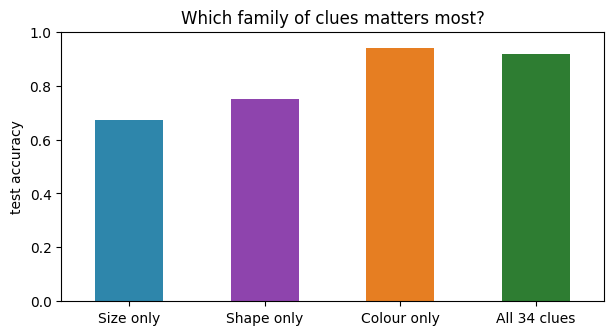

{'Size only': '67.2%', 'Shape only': '75.0%', 'Colour only': '93.9%', 'All 34 clues': '91.7%'}


In [32]:
results = {}
for family_name, columns in [("Size only", SIZE), ("Shape only", SHAPE), ("Colour only", COLOUR)]:
    # TODO: build the same pipeline, fit on X_train[columns], and store the test accuracy in results[family_name]
    model = make_pipeline(StandardScaler(), OneVsRestClassifier(LogisticRegression(max_iter=1000)))
    model.fit(X_train[columns], y_train)
    results[family_name] = accuracy_score(y_test, model.predict(X_test[columns]))

results["All 34 clues"] = acc_full
pd.Series(results).plot(kind="bar", color=["#2E86AB", "#8E44AD", "#E67E22", "#2E7D32"], figsize=(7, 3.5), rot=0)
plt.ylim(0, 1); plt.ylabel("test accuracy"); plt.title("Which family of clues matters most?"); plt.show()
print({k: f"{v:.1%}" for k, v in results.items()})

In [33]:
# ✅ Check
assert results["Colour only"] > results["Shape only"] > results["Size only"]
print("✅ Ranking found:", " > ".join(sorted(results, key=results.get, reverse=True)))

✅ Ranking found: Colour only > All 34 clues > Shape only > Size only


### 🎯 Mini-challenge: only 8 clues
In Lab 3 you learned to **read θ**: a weight far from 0 means the clue has a strong effect.
Here we have 7 classifiers, so we take the **average absolute weight** of each clue over the 7 classifiers, and keep the **8 strongest**.

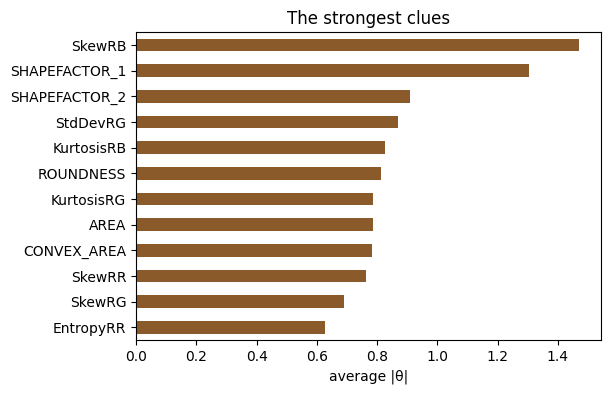

In [34]:
# Run this cell: average |θ| of each clue over the 7 one-vs-all classifiers
weights = np.mean([np.abs(clf.coef_[0]) for clf in detective[-1].estimators_], axis=0)
importance = pd.Series(weights, index=X.columns).sort_values(ascending=False)
importance.head(12).plot(kind="barh", figsize=(6, 4), color="#8B5A2B").invert_yaxis()
plt.xlabel("average |θ|"); plt.title("The strongest clues"); plt.show()

In [35]:
# TODO: keep the names of the 8 strongest clues (hint: importance.index[:8])
TOP8 = list(importance.index[:8])

# TODO: train the same pipeline on these 8 clues only and compute the test accuracy
detective_8 = make_pipeline(StandardScaler(), OneVsRestClassifier(LogisticRegression(max_iter=1000)))
detective_8.fit(X_train[TOP8], y_train)

acc_8 = accuracy_score(y_test, detective_8.predict(X_test[TOP8]))
print("8 clues:", TOP8)
print(f"8 clues: {acc_8:.1%}   vs   34 clues: {acc_full:.1%}")

8 clues: ['SkewRB', 'SHAPEFACTOR_1', 'SHAPEFACTOR_2', 'StdDevRG', 'KurtosisRB', 'ROUNDNESS', 'KurtosisRG', 'AREA']
8 clues: 91.1%   vs   34 clues: 91.7%


✍️ **Q9.** (a) Which family of clues is the strongest? Does this make sense for dates?
(b) Compare **colour only** with **all 34 clues**. What surprises you? Why can **more clues** sometimes give a **worse** model?
(c) With only 8 clues, how much accuracy did you lose? Would you advise Abu Fahad to use 8, 18 (colour) or 34 clues? Think about cost, speed and mistakes.

✍️ **Your answer (Q9):**

a. The strongest family of clues is COLOR, and it's pretty logical for a dates dataset as humans can usually sort them with color too.

b. I was surprised to find that only one group could give better results than all the clues combined. The reason why more clues can sometimes give a worse model is because some features may contain irrelevant information, which can make it harder for the model to generalise.

c. Using only 8 clues reduced the accuracy by just 0.6 percentage points compared with using all 34 clues.

d. I would advise Abu Fahad to use the only color group, because they achieve the highest accuracy while using fewer features than the full 34. This reduces complexity and prediction time while making fewer mistakes. However, if speed and simplicity are more important than the small accuracy difference, the 8 clues are also a good option.

---
# Step 10 · The application: the Sorting Gate 🚪

Abu Fahad's second wish: *"Warn me when you are **not sure**."*

`predict_proba` gives the probability of each variety. The highest probability is the detective's **confidence**.

**The Sorting Gate rule:**
- confidence **≥ threshold** → ✅ **auto-sort** the date
- confidence **< threshold** → 🧑‍🔬 send it to a **human inspector**

In [36]:
proba = detective.predict_proba(X_test)        # shape (180, 7)
confidence = proba.max(axis=1)                 # the highest probability for each date
correct = (y_pred == y_test.values)            # True when the detective was right

print("Average confidence when RIGHT:", confidence[correct].mean().round(2))
print("Average confidence when WRONG:", confidence[~correct].mean().round(2))

Average confidence when RIGHT: 0.88
Average confidence when WRONG: 0.53


The detective is **less confident when it is wrong**. That is exactly what makes a gate useful.

In [37]:
def sorting_gate(threshold):
    """Return (share of dates auto-sorted, accuracy on the auto-sorted dates)."""
    # TODO: auto = a boolean array, True when confidence >= threshold
    auto = confidence >= threshold
    # TODO: share of dates that are auto-sorted (hint: auto.mean())
    share_auto = auto.mean()
    # TODO: accuracy on the auto-sorted dates only (hint: correct[auto].mean())
    acc_auto = correct[auto].mean()
    return share_auto, acc_auto

for t in [0.5, 0.6, 0.7, 0.8, 0.9]:
    s, a = sorting_gate(t)
    print(f"threshold {t:.1f} → auto-sorted {s:5.1%} of dates, accuracy {a:5.1%} | inspector checks {1 - s:5.1%}")

threshold 0.5 → auto-sorted 95.6% of dates, accuracy 94.8% | inspector checks  4.4%
threshold 0.6 → auto-sorted 90.6% of dates, accuracy 98.2% | inspector checks  9.4%
threshold 0.7 → auto-sorted 81.7% of dates, accuracy 99.3% | inspector checks 18.3%
threshold 0.8 → auto-sorted 72.8% of dates, accuracy 99.2% | inspector checks 27.2%
threshold 0.9 → auto-sorted 52.2% of dates, accuracy 100.0% | inspector checks 47.8%


In [38]:
# ✅ Check
s, a = sorting_gate(0.8)
assert abs(s - 0.728) < 0.01 and a > 0.98
print(f"✅ At 0.8: {s:.1%} of dates are auto-sorted with {a:.1%} accuracy")

✅ At 0.8: 72.8% of dates are auto-sorted with 99.2% accuracy


### 🕵️ Did the gate solve the Safawi complaint?
In Step 8 we found **4 "fake Safawi"** (other dates predicted as SAFAVI). How many of them would **pass** the gate and reach the customer's box?

In [39]:
fake_safavi = (y_pred == "SAFAVI") & ~correct     # predicted SAFAVI but wrong
print("Confidence of the 4 fake Safawi:", np.round(confidence[fake_safavi], 2))

# TODO: for each threshold, count the fake Safawi with confidence >= threshold
for t in [0.5, 0.6, 0.7, 0.8]:
    passing = fake_safavi & (confidence >= t)
    print(f"threshold {t:.1f} → fake Safawi packed: {passing.sum()}")

Confidence of the 4 fake Safawi: [0.5  0.51 0.5  0.33]
threshold 0.5 → fake Safawi packed: 2
threshold 0.6 → fake Safawi packed: 0
threshold 0.7 → fake Safawi packed: 0
threshold 0.8 → fake Safawi packed: 0


🎉 The detective was **unsure** about every fake Safawi (confidence about 0.5 or less). With a gate at **0.6 or higher**, **none** of them reaches the customer: they all go to the inspector.

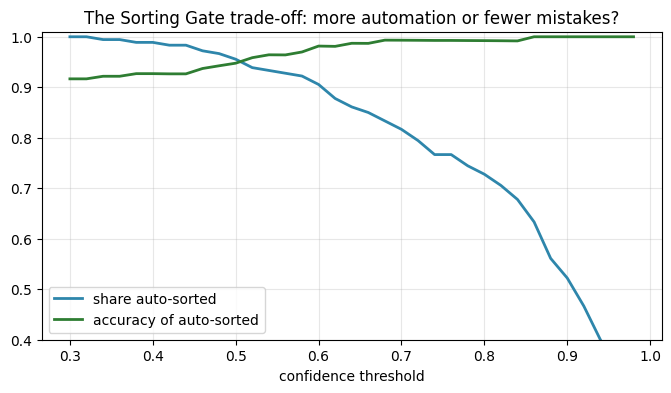

In [40]:
# Run this cell: the trade-off curve
thresholds = np.linspace(0.3, 0.98, 35)
shares, accs = zip(*[sorting_gate(t) for t in thresholds])
fig, ax1 = plt.subplots(figsize=(8, 4))
ax1.plot(thresholds, shares, color="#2E86AB", lw=2, label="share auto-sorted")
ax1.plot(thresholds, accs, color="#2E7D32", lw=2, label="accuracy of auto-sorted")
ax1.set_xlabel("confidence threshold"); ax1.set_ylim(0.4, 1.01); ax1.legend(loc="lower left"); ax1.grid(alpha=0.3)
ax1.set_title("The Sorting Gate trade-off: more automation or fewer mistakes?"); plt.show()

### 🏭 The gate in action
This is the function that would run on the factory belt, one date at a time.

In [50]:
GATE = 0.6   # TODO (optional): change this to the threshold you choose for Abu Fahad

def sort_date(measurements):
    """measurements: one row of 34 clues. Returns the decision as a sentence."""
    p = detective.predict_proba(measurements.to_frame().T)[0]
    best = p.argmax()
    variety, conf = detective.classes_[best], p[best]
    if conf >= GATE:
        return f"{variety:7s} · {conf:4.0%} sure → ✅ AUTO-SORT"
    return f"{variety:7s} · {conf:4.0%} sure → 🧑‍🔬 SEND TO INSPECTOR"

for i in range(8):
    print(f"date #{i+1}  (truly {y_test.iloc[i]:7s}) :", sort_date(X_test.iloc[i]))

date #1  (truly DEGLET ) : DEGLET  ·  88% sure → ✅ AUTO-SORT
date #2  (truly ROTANA ) : ROTANA  ·  82% sure → ✅ AUTO-SORT
date #3  (truly ROTANA ) : ROTANA  ·  93% sure → ✅ AUTO-SORT
date #4  (truly SAFAVI ) : SAFAVI  ·  99% sure → ✅ AUTO-SORT
date #5  (truly BERHI  ) : BERHI   ·  95% sure → ✅ AUTO-SORT
date #6  (truly DOKOL  ) : DOKOL   ·  94% sure → ✅ AUTO-SORT
date #7  (truly DOKOL  ) : DOKOL   ·  87% sure → ✅ AUTO-SORT
date #8  (truly SOGAY  ) : SOGAY   ·  71% sure → ✅ AUTO-SORT


✍️ **Q10.** (a) Which threshold do you choose for the factory, and why? Give the two numbers (auto-sorted %, accuracy %).
(b) What happens if the threshold is **too high**? **Too low**?
(c) Name one **other** real application where a model should say "I am not sure, ask a human".

✍️ **Your answer (Q10):**

a. I would choose a 0.60 threshold as it is the sweet point between auto sorting and accuracy of sorted dates, at 91% and 98.2% respectively. It also prevents all four incorrectly predicted SAFAVI dates in the test set from reaching the customer.

b. When a threshold is too high, almost every date will go to an inspector and accuracy among automatically sorted dates generally increases. When it's too low, all dates will get auto-sorted however, with more mistakes that pass through so more wrong dates can reach customers.

c. Another real application would be with cancer images as they are very sensitive readings and have to a higher threshold. If a model is uncertain about whether an image shows cancer, it should refer the image to a qualified specialist rather than make an automatic decision.

---
# Step 11 · Report to Abu Fahad 📝

Abu Fahad is not a data scientist. Write **5 short lines** he can understand. Use **your** numbers.

1. **Result:** ...
2. **What the model gets wrong:** ...
3. **The Safawi complaint:** ...
4. **The Sorting Gate:** ...
5. **My recommendation:** ...

✍️ **Your answer (Step 11):**

The model recognises 92 of every 100 dates. DEGLET is the hardest variety to recognise, with 65% recall. It is most often confused with DOKOL. Out of 44 dates predicted as SAFAVI, 4 were actually other varieties. With a threshold of 0.6, none of these 4 incorrect predictions passes the Sorting Gate in the test set.
With a threshold of 0.6, approximately 90 out of 100 dates are automatically sorted with 98.2% accuracy. The remaining 10 go to human inspectors.
I recommend the factory to test the 18 colour measurements because they performed better (93.9% accuracy) than the full 34-feature model. Test their own Sorting Gate before using them in the factory.

---
# ★ Optional challenge: a colour-only Sorting Gate

In Step 9 the **colour-only** detective (18 clues) beat the full detective (34 clues).
Build the Sorting Gate with the **colour-only** detective and compare it with your gate at **0.8**:
1. Train the colour-only pipeline and compute its `confidence` and `correct` arrays.
2. At threshold 0.8: what share of dates is auto-sorted, and with what accuracy?
3. Which gate would you install at the factory? Why?

In [47]:
# Build the colour-only pipeline
detective_colour = make_pipeline(
    StandardScaler(),
    OneVsRestClassifier(LogisticRegression(max_iter=1000))
)

# Train using ONLY the colour features
detective_colour.fit(X_train[COLOUR], y_train)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('onevsrestclassifier',
                 OneVsRestClassifier(estimator=LogisticRegression(max_iter=1000)))])

In [48]:
# Predict the varieties
y_pred_colour = detective_colour.predict(X_test[COLOUR])

# Get probabilities
proba_colour = detective_colour.predict_proba(X_test[COLOUR])

# Get the highest probability for each date
confidence_colour = proba_colour.max(axis=1)

# Check whether predictions are correct
correct_colour = (y_pred_colour == y_test.values)

In [49]:
threshold = 0.8

# Which dates pass the gate?
auto_colour = confidence_colour >= threshold

# Percentage of dates automatically sorted
share_auto_colour = auto_colour.mean()

# Accuracy on automatically sorted dates
acc_auto_colour = correct_colour[auto_colour].mean()

print(f"Colour-only gate at 0.8:")
print(f"Auto-sorted: {share_auto_colour:.1%}")
print(f"Accuracy: {acc_auto_colour:.1%}")
print(f"Inspector checks: {1 - share_auto_colour:.1%}")

Colour-only gate at 0.8:
Auto-sorted: 54.4%
Accuracy: 98.0%
Inspector checks: 45.6%


✍️ **Your answer (challenge):**

The colour-only gate automatically sorts 54.4% of dates with 98% accuracy, while the full model automatically sorts 72.8% with 99.2% accuracy.

I would choose the full model because it sorts more dates automatically, achieves higher accuracy, and requires fewer human inspections. However, the colour-only model is still a good alternative if reducing the number of measurements is more important.

---
## ✅ Submission checklist
1. All cells run from top to bottom without errors.
2. Every `# TODO` is completed and every ✅ check passes.
3. All ✍️ questions (Q1–Q10) are answered in your own words.
4. Your 5-line report to Abu Fahad uses **your** numbers.
5. Download your notebook (**File → Download → .ipynb**) and submit it on Blackboard.

🌴 *Case closed, detective!*